# 05 · Adding amusement: stress vs non-stress, and 3-class

Notebooks 02–04 solve **baseline (1) vs stress (2)**. Here the **amusement** condition (label 3, ≈ 6 min of funny
video clips per subject) is added in the two ways used in the WESAD paper:

| task | classes | windows (reshape) |
|---|---|---|
| baseline vs stress (notebooks 02–04) | 1 / 2 | 1,671 / 904 |
| **stress vs non-stress** | 1 + 3 (merged) / 2 | 2,136 / 904 |
| **3-class** | 1 / 2 / 3 | 1,671 / 904 / 465 |

Everything else is unchanged: 1-min windows from `reshape_function` (notebook 01), no per-subject normalisation,
LOSO over the 15 subjects, the same four classifiers, and every decomposition applied to each window on its own.
The windows, decompositions and features of labels 1 and 2 are the cached ones of notebooks 02–04
(`cache/reshape/label1/`, `label2/`); only the 465 amusement windows were added (`label3/`).

**No re-tuning.** The `gmsEDA` configuration (20 chops, overlap 0.9, λ-scale 1) is the one chosen on the binary
task in notebook 02. For the two new tasks it is therefore a fixed, pre-specified choice, so its results here are
not inflated by selection. Section 3 additionally lets the configuration be chosen inside each LOSO fold.

**Metrics.** The classes are imbalanced, so besides accuracy we report **macro-F1** and **balanced accuracy**
(mean recall over classes). Always guessing the majority class gives accuracy 0.649 / 0.703 / 0.549 for the three
tasks, and balanced accuracy 0.5 / 0.5 / 0.333.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings("ignore")
from eda_utils import *
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

WINDOWING = "reshape"
STRIDE = 10
BEST = "c20_o0.9_l1_nn0"                 # chosen in notebook 02 (binary task)
TASKS = {
    "baseline vs stress": dict(labels=(1, 2), merge={}),
    "stress vs non-stress": dict(labels=(1, 2, 3), merge={3: 1}),
    "3-class": dict(labels=(1, 2, 3), merge={}),
}
CLASS_NAMES = {"baseline vs stress": ["baseline", "stress"],
               "stress vs non-stress": ["non-stress", "stress"],
               "3-class": ["baseline", "stress", "amusement"]}
DATA = {}
for task, cfg in TASKS.items():
    W, meta = load_windows(WINDOWING, cfg["labels"], STRIDE)
    y = task_labels(meta, cfg["merge"])
    DATA[task] = dict(W=W, meta=meta, y=y, groups=meta.subject.values)
    vc = pd.Series(y).value_counts().sort_index()
    print(f"{task:22s} {len(y)} windows, classes {vc.to_dict()}, majority-class accuracy {vc.max() / len(y):.3f}")

baseline vs stress     2575 windows, classes {1: 1671, 2: 904}, majority-class accuracy 0.649
stress vs non-stress   3040 windows, classes {1: 2136, 2: 904}, majority-class accuracy 0.703
3-class                3040 windows, classes {1: 1671, 2: 904, 3: 465}, majority-class accuracy 0.550


## 1. Feature sets of notebooks 02–03 (my features)
All tables are read from the per-label caches (`own_features`); nothing is recomputed for labels 1 and 2.

In [2]:
def own_sets(labels):
    raw = own_features(WINDOWING, labels, "raw")
    RAW = raw[[c for c in raw if not c.startswith("rel_")]]
    gms = own_features(WINDOWING, labels, BEST)
    return {
        "raw": RAW,
        "raw + running median": pd.concat([RAW, own_features(WINDOWING, labels, "med")], axis=1),
        "raw + NeuroKit2 highpass": pd.concat([RAW, own_features(WINDOWING, labels, "nk_highpass")], axis=1),
        "raw + NeuroKit2 smoothmedian": pd.concat([RAW, own_features(WINDOWING, labels, "nk_median")], axis=1),
        "raw + sparsEDA": pd.concat([RAW, own_features(WINDOWING, labels, "sparsEDA")], axis=1),
        "raw + gmsEDA (tonic/phasic only)": pd.concat([RAW, gms[[c for c in gms if "drv" not in c]]], axis=1),
        "raw + gmsEDA (full)": pd.concat([RAW, gms], axis=1),
    }

t0 = time.time()
RES_OWN, P_OWN = {}, {}
for task, cfg in TASKS.items():
    d = DATA[task]
    sets = own_sets(cfg["labels"])
    RES_OWN[task], P_OWN[task] = compare_feature_sets_cached(       # cached in results/labels_.../
        sets, d["y"], d["groups"], results_dir(WINDOWING, cfg["labels"], cfg["merge"]) / "own_features")
print(f"{time.time() - t0:.0f}s")

def summary(RES, metric):
    t = pd.DataFrame({task: r.groupby("features", sort=False)[metric].mean() for task, r in RES.items()})
    return t

METRICS = {"accuracy": "acc", "macro-F1": "f1", "balanced accuracy": "bacc"}
print("Mean over the 4 classifiers")
pd.concat({name: summary(RES_OWN, m) for name, m in METRICS.items()}, axis=1).round(3)

709s
Mean over the 4 classifiers


accuracy                                        macro-F1                               balanced accuracy                             
                                 baseline vs stress stress vs non-stress 3-class baseline vs stress stress vs non-stress 3-class baseline vs stress stress vs non-stress 3-class
features                                                                                                                                                                        
raw                                           0.840                0.829   0.679              0.819                0.784   0.523              0.810                0.770   0.534
raw + running median                          0.844                0.840   0.689              0.824                0.799   0.538              0.817                0.788   0.548
raw + NeuroKit2 highpass                      0.846                0.838   0.686              0.826                0.796   0.531              0.816                0.784   0.542
raw + NeuroKit2 smoothmedian                  0.849                0.840   0.686              0.829                0.799   0.534              0.821                0.786   0.544
raw + sparsEDA                                0.840                0.830   0.689              0.819                0.786   0.537              0.811                0.773   0.548
raw + gmsEDA (tonic/phasic only)              0.849                0.846   0.697              0.830                0.807   0.544              0.822                0.795   0.554
raw + gmsEDA (full)                           0.866                0.868   0.708              0.849                0.836   0.560              0.843                0.824   0.568

Per classifier, and the paired per-subject test against `raw` (Δ mean subject accuracy, subjects improved / worse,
Wilcoxon p):

In [3]:
def per_model(RES):
    out = {}
    for task, r in RES.items():
        acc = r.pivot(index="features", columns="model", values="acc").loc[r.features.unique()]
        acc["mean"] = acc.mean(axis=1)
        out[task] = acc
    return pd.concat(out).round(3)

def paired_cells(P, RES):
    return pd.concat({task: p.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1))
                      .pivot(index="features", columns="model", values="cell").loc[RES[task].features.unique()[1:]]
                      for task, p in P.items()})

display(per_model(RES_OWN))
paired_cells(P_OWN, RES_OWN)

model                                                  HistGB  LogReg  RandomForest  SVM-RBF   mean
                     features                                                                      
baseline vs stress   raw                                0.843   0.833         0.829    0.855  0.840
                     raw + running median               0.846   0.828         0.834    0.866  0.844
                     raw + NeuroKit2 highpass           0.855   0.831         0.842    0.857  0.846
                     raw + NeuroKit2 smoothmedian       0.849   0.831         0.847    0.867  0.849
                     raw + sparsEDA                     0.838   0.829         0.843    0.851  0.840
                     raw + gmsEDA (tonic/phasic only)   0.846   0.842         0.833    0.875  0.849
                     raw + gmsEDA (full)                0.859   0.866         0.855    0.882  0.866
stress vs non-stress raw                                0.815   0.850         0.820    0.830  0.829
                     raw + running median               0.836   0.840         0.842    0.841  0.840
                     raw + NeuroKit2 highpass           0.834   0.844         0.837    0.836  0.838
                     raw + NeuroKit2 smoothmedian       0.837   0.838         0.842    0.842  0.840
                     raw + sparsEDA                     0.820   0.837         0.832    0.830  0.830
                     raw + gmsEDA (tonic/phasic only)   0.840   0.852         0.842    0.850  0.846
                     raw + gmsEDA (full)                0.858   0.875         0.863    0.877  0.868
3-class              raw                                0.663   0.699         0.640    0.715  0.679
                     raw + running median               0.685   0.686         0.657    0.727  0.689
                     raw + NeuroKit2 highpass           0.675   0.692         0.656    0.723  0.686
                     raw + NeuroKit2 smoothmedian       0.681   0.687         0.648    0.728  0.686
                     raw + sparsEDA                     0.685   0.690         0.661    0.721  0.689
                     raw + gmsEDA (tonic/phasic only)   0.683   0.710         0.664    0.731  0.697
                     raw + gmsEDA (full)                0.693   0.720         0.677    0.741  0.708

model                                                                  HistGB                  LogReg            RandomForest                 SVM-RBF
                     features                                                                                                                        
baseline vs stress   raw + running median               +0.003 (6/5, p=0.657)   -0.005 (6/7, p=0.727)   +0.006 (7/4, p=0.657)  +0.011 (10/3, p=0.033)
                     raw + NeuroKit2 highpass          +0.012 (10/4, p=0.096)   -0.002 (6/7, p=0.701)   +0.014 (9/5, p=0.397)   +0.002 (5/6, p=0.533)
                     raw + NeuroKit2 smoothmedian       +0.006 (9/4, p=0.221)   -0.002 (7/6, p=0.972)  +0.019 (10/2, p=0.071)  +0.012 (10/2, p=0.028)
                     raw + sparsEDA                     -0.005 (6/7, p=0.382)   -0.004 (7/6, p=0.972)   +0.014 (9/4, p=0.279)   -0.004 (5/9, p=0.433)
                     raw + gmsEDA (tonic/phasic only)  +0.003 (10/4, p=0.103)   +0.010 (8/6, p=0.433)   +0.005 (8/4, p=0.367)  +0.020 (11/3, p=0.016)
                     raw + gmsEDA (full)               +0.017 (11/3, p=0.198)  +0.033 (11/2, p=0.055)  +0.027 (11/3, p=0.056)  +0.027 (11/3, p=0.006)
stress vs non-stress raw + running median               +0.020 (9/4, p=0.033)   -0.010 (6/8, p=0.470)  +0.022 (11/3, p=0.064)   +0.011 (7/5, p=0.239)
                     raw + NeuroKit2 highpass           +0.019 (9/5, p=0.035)   -0.006 (6/8, p=0.594)  +0.017 (10/3, p=0.075)   +0.005 (7/6, p=0.382)
                     raw + NeuroKit2 smoothmedian       +0.021 (9/5, p=0.026)   -0.013 (5/8, p=0.311)   +0.023 (9/4, p=0.064)   +0.012 (8/6, p=0.140)
                     raw + sparsEDA                     +0.004 (7/6, p=0.650)  -0.013 (2/11, p=0.028)   +0.012 (9/5, p=0.140)   -0.000 (7/7, p=0.975)
                     raw + gmsEDA (tonic/phasic only)  +0.025 (11/2, p=0.016)   +0.001 (8/5, p=0.552)  +0.023 (11/3, p=0.030)  +0.020 (11/3, p=0.011)
                     raw + gmsEDA (full)               +0.043 (10/4, p=0.064)  +0.025 (10/2, p=0.084)  +0.044 (13/1, p=0.008)  +0.047 (13/1, p=0.002)
3-class              raw + running median               +0.022 (8/6, p=0.209)   -0.013 (6/9, p=0.359)  +0.017 (11/2, p=0.019)   +0.012 (9/4, p=0.069)
                     raw + NeuroKit2 highpass           +0.012 (7/8, p=0.639)   -0.007 (7/8, p=0.842)   +0.016 (9/4, p=0.101)   +0.008 (8/5, p=0.221)
                     raw + NeuroKit2 smoothmedian       +0.018 (9/6, p=0.277)   -0.012 (6/9, p=0.379)   +0.008 (9/4, p=0.382)   +0.013 (8/5, p=0.075)
                     raw + sparsEDA                    +0.022 (10/4, p=0.109)   -0.009 (7/6, p=0.311)  +0.020 (10/3, p=0.019)   +0.006 (7/8, p=0.454)
                     raw + gmsEDA (tonic/phasic only)  +0.021 (10/3, p=0.133)  +0.011 (11/4, p=0.293)  +0.024 (11/3, p=0.026)  +0.016 (10/5, p=0.164)
                     raw + gmsEDA (full)               +0.030 (10/5, p=0.107)  +0.022 (11/4, p=0.118)  +0.037 (13/1, p=0.016)  +0.026 (11/2, p=0.007)

### Head-to-head: `raw + gmsEDA (full)` against the best other decomposition, for each task

In [4]:
rows = []
for task, cfg in TASKS.items():
    d = DATA[task]
    sets = own_sets(cfg["labels"])
    m = summary(RES_OWN, "acc")[task]
    others = ["raw + NeuroKit2 highpass", "raw + NeuroKit2 smoothmedian", "raw + sparsEDA"]
    ref = max(others, key=lambda k: m[k])
    _, h = compare_feature_sets_cached({ref: sets[ref], "raw + gmsEDA (full)": sets["raw + gmsEDA (full)"]},
                                       d["y"], d["groups"], results_dir(WINDOWING, cfg["labels"], cfg["merge"]) / "own_h2h",
                                       baseline=ref)
    rows += [dict(task=task, reference=ref, model=r.model, delta=r.delta, wins=r.wins, losses=r.losses, p=r.p)
             for r in h.itertuples()]
H2H = pd.DataFrame(rows)
H2H.assign(cell=lambda d: d.apply(lambda r: f"{r.delta:+.3f} ({r.wins}/{r.losses}, p={r.p:.3f})", axis=1)) \
   .pivot(index=["task", "reference"], columns="model", values="cell")

,model,HistGB,LogReg,RandomForest,SVM-RBF
task,reference,,,,
3-class,raw + sparsEDA,"+0.008 (11/4, p=0.303)","+0.031 (12/3, p=0.055)","+0.017 (9/4, p=0.075)","+0.020 (14/1, p=0.005)"
baseline vs stress,raw + NeuroKit2 smoothmedian,"+0.011 (10/3, p=0.328)","+0.035 (11/2, p=0.033)","+0.008 (9/4, p=0.196)","+0.015 (9/4, p=0.100)"
stress vs non-stress,raw + NeuroKit2 smoothmedian,"+0.022 (9/4, p=0.208)","+0.038 (10/4, p=0.009)","+0.021 (10/4, p=0.056)","+0.035 (13/0, p=0.001)"


## 2. The original feature set (notebook 04)
`eda_proj.features.sig2features` descriptives + `eda_peaks` SCR features (48), and the 12 driver descriptives
(60). All classifiers get a median imputer, as in notebook 04.

In [5]:
def orig_sets(labels):
    F = lambda k: orig_features(WINDOWING, labels, k)
    return {
        "raw (12)": F("raw"),
        "raw + NeuroKit2 highpass": F("nk_highpass"),
        "raw + NeuroKit2 smoothmedian": F("nk_smoothmedian"),
        "raw + sparsEDA": F("sparsEDA"),
        "raw + sparsEDA + driver": F("sparsEDA_drv"),
        "raw + gmsEDA c20 o0.9 λ1": F("gms_c20_o0.9_l1"),
        "raw + gmsEDA c20 o0.9 λ1 + driver": F("gms_c20_o0.9_l1_drv"),
    }

t0 = time.time()
MODELS = models_with_imputer()
RES_ORIG, P_ORIG = {}, {}
for task, cfg in TASKS.items():
    d = DATA[task]
    RES_ORIG[task], P_ORIG[task] = compare_feature_sets_cached(
        orig_sets(cfg["labels"]), d["y"], d["groups"], results_dir(WINDOWING, cfg["labels"], cfg["merge"]) / "orig_features",
        models=MODELS, baseline="raw (12)")
print(f"{time.time() - t0:.0f}s")
print("Mean over the 4 classifiers (original features)")
pd.concat({name: summary(RES_ORIG, m) for name, m in METRICS.items()}, axis=1).round(3)

685s
Mean over the 4 classifiers (original features)


accuracy                                        macro-F1                               balanced accuracy                             
                                  baseline vs stress stress vs non-stress 3-class baseline vs stress stress vs non-stress 3-class baseline vs stress stress vs non-stress 3-class
features                                                                                                                                                                         
raw (12)                                       0.770                0.785   0.634              0.738                0.721   0.466              0.734                0.712   0.485
raw + NeuroKit2 highpass                       0.867                0.865   0.698              0.850                0.831   0.542              0.841                0.818   0.553
raw + NeuroKit2 smoothmedian                   0.851                0.849   0.687              0.831                0.811   0.531              0.821                0.798   0.541
raw + sparsEDA                                 0.846                0.838   0.697              0.825                0.795   0.548              0.815                0.782   0.555
raw + sparsEDA + driver                        0.845                0.840   0.707              0.824                0.798   0.562              0.814                0.785   0.568
raw + gmsEDA c20 o0.9 λ1                       0.842                0.848   0.695              0.823                0.811   0.538              0.817                0.800   0.550
raw + gmsEDA c20 o0.9 λ1 + driver              0.855                0.856   0.703              0.838                0.822   0.545              0.832                0.812   0.558

In [6]:
display(per_model(RES_ORIG))
paired_cells(P_ORIG, RES_ORIG)      # paired test vs raw (12)

model                                                   HistGB  LogReg  RandomForest  SVM-RBF   mean
                     features                                                                       
baseline vs stress   raw (12)                            0.792   0.771         0.740    0.776  0.770
                     raw + NeuroKit2 highpass            0.877   0.836         0.868    0.887  0.867
                     raw + NeuroKit2 smoothmedian        0.855   0.832         0.860    0.857  0.851
                     raw + sparsEDA                      0.827   0.847         0.846    0.865  0.846
                     raw + sparsEDA + driver             0.828   0.843         0.849    0.861  0.845
                     raw + gmsEDA c20 o0.9 λ1            0.839   0.835         0.823    0.871  0.842
                     raw + gmsEDA c20 o0.9 λ1 + driver   0.844   0.848         0.839    0.890  0.855
stress vs non-stress raw (12)                            0.813   0.766         0.759    0.801  0.785
                     raw + NeuroKit2 highpass            0.866   0.843         0.868    0.882  0.865
                     raw + NeuroKit2 smoothmedian        0.856   0.830         0.855    0.857  0.849
                     raw + sparsEDA                      0.834   0.817         0.843    0.857  0.838
                     raw + sparsEDA + driver             0.833   0.819         0.852    0.858  0.840
                     raw + gmsEDA c20 o0.9 λ1            0.859   0.834         0.835    0.865  0.848
                     raw + gmsEDA c20 o0.9 λ1 + driver   0.861   0.842         0.845    0.877  0.856
3-class              raw (12)                            0.634   0.647         0.607    0.649  0.634
                     raw + NeuroKit2 highpass            0.682   0.694         0.673    0.743  0.698
                     raw + NeuroKit2 smoothmedian        0.672   0.681         0.671    0.723  0.687
                     raw + sparsEDA                      0.697   0.703         0.663    0.726  0.697
                     raw + sparsEDA + driver             0.728   0.701         0.671    0.728  0.707
                     raw + gmsEDA c20 o0.9 λ1            0.689   0.692         0.662    0.736  0.695
                     raw + gmsEDA c20 o0.9 λ1 + driver   0.692   0.704         0.671    0.746  0.703

model                                                                   HistGB                  LogReg            RandomForest                 SVM-RBF
                     features                                                                                                                         
baseline vs stress   raw + NeuroKit2 highpass           +0.085 (14/0, p=0.001)  +0.066 (14/1, p=0.000)  +0.128 (13/1, p=0.002)  +0.110 (14/0, p=0.001)
                     raw + NeuroKit2 smoothmedian       +0.063 (14/0, p=0.001)  +0.061 (11/2, p=0.004)  +0.120 (12/2, p=0.002)  +0.081 (14/1, p=0.000)
                     raw + sparsEDA                      +0.035 (9/2, p=0.021)  +0.077 (13/2, p=0.001)  +0.105 (13/1, p=0.002)  +0.088 (14/1, p=0.000)
                     raw + sparsEDA + driver            +0.035 (12/2, p=0.003)  +0.073 (13/2, p=0.001)  +0.109 (12/2, p=0.002)  +0.084 (13/1, p=0.002)
                     raw + gmsEDA c20 o0.9 λ1           +0.047 (10/3, p=0.016)  +0.064 (12/2, p=0.002)  +0.084 (12/1, p=0.005)  +0.095 (14/0, p=0.001)
                     raw + gmsEDA c20 o0.9 λ1 + driver  +0.053 (12/2, p=0.011)  +0.078 (13/2, p=0.005)  +0.100 (12/1, p=0.004)  +0.113 (14/0, p=0.001)
stress vs non-stress raw + NeuroKit2 highpass           +0.053 (13/1, p=0.008)  +0.077 (11/3, p=0.004)  +0.108 (13/1, p=0.002)  +0.082 (14/1, p=0.000)
                     raw + NeuroKit2 smoothmedian       +0.042 (12/1, p=0.002)  +0.065 (12/3, p=0.005)  +0.095 (13/0, p=0.001)  +0.056 (13/2, p=0.002)
                     raw + sparsEDA                     +0.021 (10/3, p=0.069)  +0.051 (12/3, p=0.003)  +0.083 (13/1, p=0.002)  +0.056 (13/1, p=0.002)
                     raw + sparsEDA + driver            +0.020 (10/4, p=0.035)  +0.053 (12/3, p=0.002)  +0.092 (14/0, p=0.001)  +0.057 (12/3, p=0.003)
                     raw + gmsEDA c20 o0.9 λ1           +0.046 (13/1, p=0.005)  +0.068 (11/3, p=0.008)  +0.076 (11/2, p=0.004)  +0.065 (13/2, p=0.000)
                     raw + gmsEDA c20 o0.9 λ1 + driver  +0.048 (12/2, p=0.019)  +0.077 (12/3, p=0.003)  +0.087 (13/1, p=0.002)  +0.077 (14/0, p=0.001)
3-class              raw + NeuroKit2 highpass           +0.048 (13/1, p=0.003)  +0.047 (12/3, p=0.010)  +0.067 (13/1, p=0.001)  +0.094 (13/1, p=0.002)
                     raw + NeuroKit2 smoothmedian       +0.038 (10/3, p=0.009)   +0.033 (8/6, p=0.096)  +0.065 (13/1, p=0.002)  +0.074 (12/2, p=0.004)
                     raw + sparsEDA                     +0.063 (12/3, p=0.027)  +0.056 (13/2, p=0.002)  +0.056 (14/0, p=0.001)  +0.076 (13/2, p=0.001)
                     raw + sparsEDA + driver            +0.094 (13/2, p=0.006)  +0.054 (13/2, p=0.002)  +0.065 (13/1, p=0.001)  +0.079 (13/2, p=0.001)
                     raw + gmsEDA c20 o0.9 λ1           +0.056 (12/3, p=0.003)  +0.045 (12/3, p=0.016)  +0.056 (12/2, p=0.006)  +0.087 (13/1, p=0.001)
                     raw + gmsEDA c20 o0.9 λ1 + driver  +0.058 (13/2, p=0.007)  +0.057 (10/4, p=0.041)  +0.065 (12/2, p=0.009)  +0.096 (14/0, p=0.001)

## 3. Nested LOSO for the two new tasks: `gmsEDA` configuration chosen inside each fold
As in notebook 02 section 4: candidates are `raw` alone and `raw + gms` for all 112 configurations; the choice is
made by LogReg with inner 5-fold group CV on the 14 training subjects, then refit with LogReg and HistGB.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
SEL = {"LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
       "HistGB": lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.03, max_depth=3, random_state=0)}
NEST = {}
for task in ["stress vs non-stress", "3-class"]:
    cfg, d = TASKS[task], DATA[task]
    raw = own_features(WINDOWING, cfg["labels"], "raw")
    RAW = raw[[c for c in raw if not c.startswith("rel_")]]
    CANDS = {"raw (no decomposition)": RAW}
    CANDS.update({f"raw+gms [{t}]": pd.concat([RAW, own_features(WINDOWING, cfg["labels"], t)], axis=1) for t in gms_grid().tag})
    R_ = results_dir(WINDOWING, cfg["labels"], cfg["merge"])
    t0 = time.time()
    if (R_ / "nested_gms_summary.csv").exists() and (R_ / "nested_gms_selection.csv").exists():
        summ, chosen = pd.read_csv(R_ / "nested_gms_summary.csv", index_col=0), pd.read_csv(R_ / "nested_gms_selection.csv")
    else:
        summ, chosen = nested_select_loso(CANDS, d["y"], d["groups"], SEL["LogReg"], SEL)
        summ.to_csv(R_ / "nested_gms_summary.csv"); chosen.to_csv(R_ / "nested_gms_selection.csv", index=False)
    raw_acc = RES_OWN[task].query("features == 'raw'").set_index("model").acc
    NEST[task] = pd.DataFrame({"raw only": raw_acc[["LogReg", "HistGB"]], "nested": summ.acc,
                               "nested macro-F1": summ.f1})
    NEST[task]["chosen in folds"] = "; ".join(f"{k[9:-1]} ×{v}" for k, v in chosen.chosen.value_counts().items())
pd.concat(NEST).round(3)

raw only  nested  nested macro-F1                                    chosen in folds
stress vs non-stress LogReg     0.850   0.876            0.845  c40_o0.8_l1_nn0 ×11; c30_o0.8_l1_nn0 ×3; c20_o...
                     HistGB     0.815   0.857            0.821  c40_o0.8_l1_nn0 ×11; c30_o0.8_l1_nn0 ×3; c20_o...
3-class              LogReg     0.699   0.721            0.580  c30_o0.8_l1_nn0 ×10; c40_o0.8_l1_nn0 ×4; c20_o...
                     HistGB     0.663   0.687            0.574  c30_o0.8_l1_nn0 ×10; c40_o0.8_l1_nn0 ×4; c20_o...

## 4. Where does the 3-class problem fail? Confusion matrices (SVM, pooled LOSO predictions)
Rows = true class, columns = predicted class, each row normalised to 1 (diagonal = recall of that class).

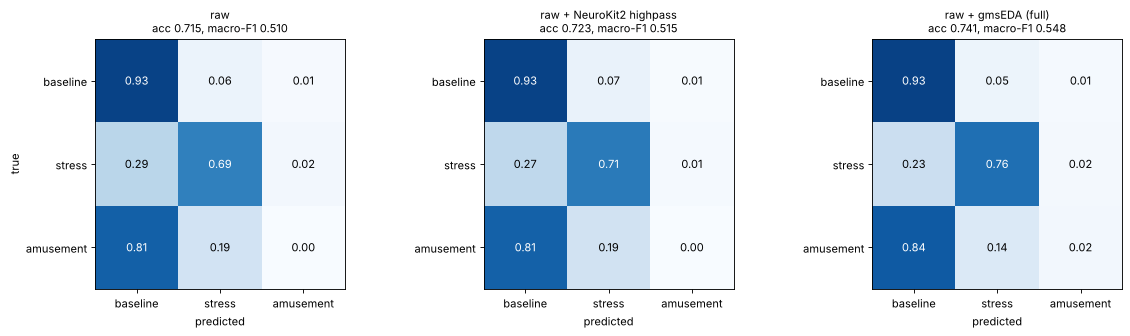

In [8]:
from sklearn.metrics import confusion_matrix
d = DATA["3-class"]; sets = own_sets((1, 2, 3)); svm = default_models()["SVM-RBF"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, ["raw", "raw + NeuroKit2 highpass", "raw + gmsEDA (full)"]):
    s, _, pred = loso_eval(svm, sets[name].values, d["y"], d["groups"], return_pred=True)
    cm = confusion_matrix(d["y"], pred, labels=[1, 2, 3], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES["3-class"]); ax.set_yticklabels(CLASS_NAMES["3-class"])
    ax.set_title(f"{name}\nacc {s['acc']:.3f}, macro-F1 {s['f1']:.3f}", fontsize=10); ax.set_xlabel("predicted")
axes[0].set_ylabel("true")
plt.tight_layout(); plt.show()

## Conclusion

Mean LOSO accuracy over the 4 classifiers (macro-F1 in brackets), reshape windows, no per-subject normalisation:

| features | baseline vs stress | stress vs non-stress | 3-class |
|---|---|---|---|
| majority class | 0.649 | 0.703 | 0.550 |
| raw (33, my features) | 0.840 (0.819) | 0.829 (0.784) | 0.679 (0.523) |
| raw + NeuroKit2 highpass | 0.846 (0.826) | 0.838 (0.796) | 0.686 (0.531) |
| raw + sparsEDA | 0.840 (0.819) | 0.830 (0.786) | 0.689 (0.537) |
| **raw + gmsEDA (20, 0.9, λ 1)** | **0.866 (0.849)** | **0.868 (0.836)** | **0.708 (0.560)** |
| original features: raw (12) | 0.770 (0.738) | 0.785 (0.721) | 0.634 (0.466) |
| original + NeuroKit2 highpass | 0.867 (0.850) | 0.865 (0.831) | 0.698 (0.542) |
| original + gmsEDA + driver | 0.855 (0.838) | 0.856 (0.822) | 0.703 (0.545) |

* **Stress vs non-stress (amusement counted with baseline): the `gmsEDA` gain is larger than in the binary task.**
  With my features it adds +3.9 points (0.829 → 0.868; macro-F1 0.784 → 0.836); 10–13 of 15 subjects improve,
  p = 0.002 (SVM) and 0.008 (RF), 0.06–0.08 for HistGB and LogReg. NeuroKit2 and sparsEDA add at most +1.1. Head-to-head
  against the best other decomposition (NeuroKit2 smoothmedian) `gmsEDA` is +2.1 to +3.8 points ahead (p = 0.001 SVM,
  0.009 LogReg). This configuration was tuned on the binary task, so it was not selected for this task.
* **Nested LOSO** (configuration chosen inside each fold) confirms it: stress vs non-stress LogReg 0.850 → 0.876,
  HistGB 0.815 → 0.857. Every fold of both new tasks chose a configuration with λ-scale 1, 20–40 chops and overlap
  0.8–0.9, the same region as in the binary task.
* **3-class:** `gmsEDA` again gives the best of my feature sets (0.679 → 0.708, macro-F1 0.523 → 0.560; significant for
  SVM and RF), but the absolute level is low. **Amusement is essentially never recognised** (recall ≤ 2 % with every
  feature set; > 80 % of amusement windows are classified as baseline, see the confusion matrices). The 3-class gain
  comes from better stress recall (SVM 0.69 → 0.76). From 1-min wrist EDA alone, amusement looks like baseline:
  both are low-arousal conditions, and EDA mainly reflects arousal.
* **Original feature set:** every decomposition again helps a lot over the 12 raw descriptives (+5 to +10 points). NeuroKit2
  highpass is best for both binary tasks (0.865 for stress vs non-stress); `gmsEDA` with driver descriptives is
  close (0.856), and in the 3-class task all decompositions are within 0.01 of each other (0.687–0.707).
* **Overall:** for stress vs non-stress the best results are `gmsEDA` with my features (0.868 mean; SVM 0.877,
  nested LogReg 0.876) and NeuroKit2 highpass with the original features (0.865). As in notebooks 02–04, `gmsEDA`'s
  advantage over the standard decompositions appears with the driver-event features, not with the original feature set.